# IIIT-CVID validation OCR EDA

Pinned archive SHA-256: `b5b562580e250ee3336462b7699bc79d0d1149d3b8cc82f1b221a0d0ce4fb489`. This notebook inspects only the released validation split, with full frame/crop/XML accounting. No model inference or test-label inspection.

In [11]:
from pathlib import Path
from collections import Counter, defaultdict
import hashlib, xml.etree.ElementTree as ET
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display
ROOT = Path.cwd()
DATA = ROOT / 'experiments/datasets/iiit_cvid/IIIT-CVid'
FRAMES = DATA / 'Frames/val'
CROPS = DATA / 'Crops/val'
assert FRAMES.is_dir() and CROPS.is_dir(), 'Validation images/XML not acquired'
frame_paths = sorted(FRAMES.rglob('*.png'))
xml_paths = sorted(FRAMES.rglob('*.xml'))
crop_paths = sorted(CROPS.rglob('*.png'))
label_files = sorted(CROPS.glob('*/Id-Label.txt'))
print('frames', len(frame_paths), 'xml', len(xml_paths), 'crops', len(crop_paths), 'label_files', len(label_files))
assert len(frame_paths) == len(xml_paths) == 549


frames 549 xml 549 crops 15379 label_files 5


In [11]:
labels = {}
duplicate_label_keys = []
for source in label_files:
    for line in source.read_text(encoding='utf-8-sig').splitlines():
        path, sep, value = line.partition(' ')
        if not sep: continue
        key = path.replace('\\', '/')
        if key in labels: duplicate_label_keys.append(key)
        labels[key] = value.strip()
crop_keys = {p.relative_to(DATA).as_posix() for p in crop_paths}
missing_crop_labels = sorted(crop_keys - labels.keys())
orphan_labels = sorted(labels.keys() - crop_keys)
rows = []
invalid_boxes = []
missing_xml = []
for image in frame_paths:
    xml = image.with_suffix('.xml')
    if not xml.exists():
        missing_xml.append(image.relative_to(DATA).as_posix())
        continue
    with Image.open(image) as im:
        width, height = im.size
        im.verify()
    tree = ET.parse(xml).getroot()
    declared = (int(tree.findtext('size/width', '0')), int(tree.findtext('size/height', '0')))
    objects = tree.findall('object')
    for idx, obj in enumerate(objects):
        box = obj.find('bndbox')
        if box is None: invalid_boxes.append((image.name, idx, 'missing'))
        else:
            coords = [int(float(box.findtext(k, '0'))) for k in ('xmin','ymin','xmax','ymax')]
            x1,y1,x2,y2 = coords
            if not (0 <= x1 < x2 <= width and 0 <= y1 < y2 <= height):
                invalid_boxes.append((image.name, idx, coords))
    rel = image.relative_to(FRAMES).parts
    rows.append(dict(course=rel[0],video=rel[1],image=image.name,width=width,height=height,
                     xml_size_mismatch=declared!=(width,height),text_objects=len(objects)))
frame_df = pd.DataFrame(rows)
print('missing_xml',len(missing_xml),'invalid_boxes',len(invalid_boxes),
      'xml_size_mismatch',int(frame_df.xml_size_mismatch.sum()))
print('crop labels',len(labels),'duplicate keys',len(duplicate_label_keys),
      'unlabeled crops',len(missing_crop_labels),'orphan labels',len(orphan_labels),
      'blank labels',sum(not x for x in labels.values()))
display(frame_df.groupby('course').agg(frames=('image','size'),videos=('video','nunique'),
                                         text_objects=('text_objects','sum'),
                                         xml_mismatches=('xml_size_mismatch','sum')))
display(frame_df[['width','height','text_objects']].describe())


missing_xml 0 invalid_boxes 3 xml_size_mismatch 3
crop labels 15379 duplicate keys 0 unlabeled crops 0 orphan labels 0 blank labels 0


,frames,videos,text_objects,xml_mismatches
course,,,,
11,129,36,2907,1
13,68,23,1452,0
19,196,46,7757,1
2,83,28,1875,1
6,73,7,1388,0


,width,height,text_objects
count,549.000000,549.000000,549.000000
mean,860.386157,541.471767,28.012750
std,237.707781,102.859720,17.216468
min,320.000000,258.000000,4.000000
25%,640.000000,482.000000,15.000000
50%,960.000000,546.000000,25.000000
75%,960.000000,610.000000,39.000000
max,1280.000000,738.000000,136.000000


crop_decode_failures 0


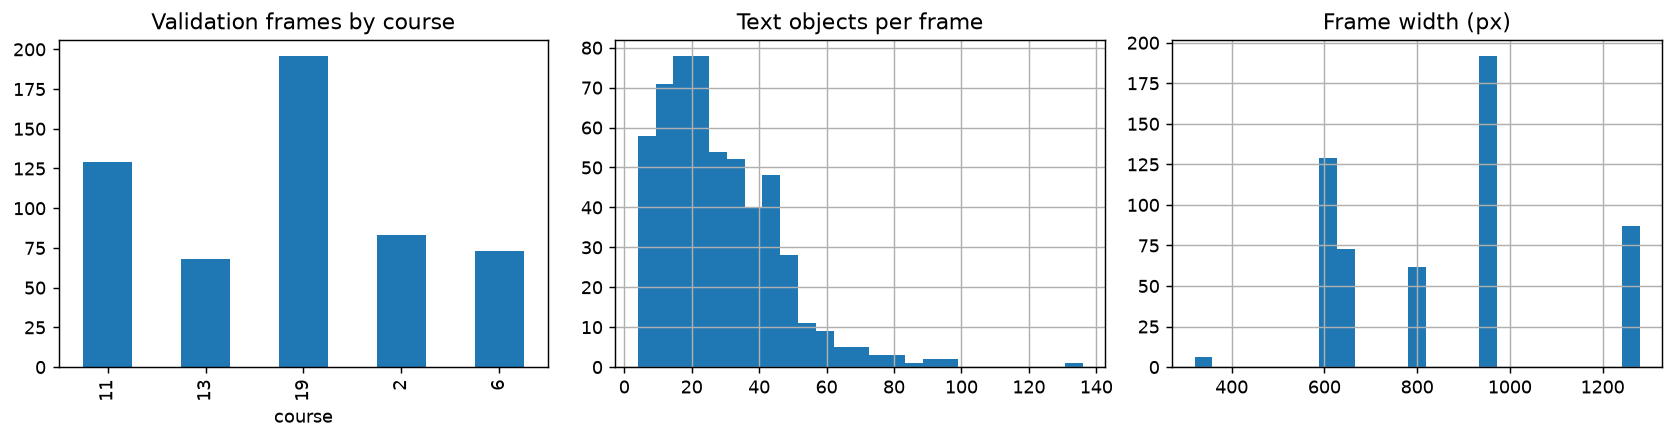

In [11]:
bad_crops = []
for image in crop_paths:
    try:
        with Image.open(image) as im: im.verify()
    except Exception as exc:
        bad_crops.append((image.relative_to(DATA).as_posix(),type(exc).__name__))
print('crop_decode_failures',len(bad_crops))
fig, axes = plt.subplots(1,3,figsize=(13,3.5))
frame_df.groupby('course').size().plot.bar(ax=axes[0],title='Validation frames by course')
frame_df.text_objects.hist(bins=25,ax=axes[1]); axes[1].set_title('Text objects per frame')
frame_df.width.hist(bins=25,ax=axes[2]); axes[2].set_title('Frame width (px)')
plt.tight_layout(); plt.show()


unique_label_strings 3889 one_character_labels 1684 exact_crop_groups_cross_video 0
label_length_quantiles {0.0: 1.0, 0.25: 2.0, 0.5: 4.0, 0.75: 7.0, 0.95: 10.0, 1.0: 22.0}
invalid_box_examples [('00_20_38_00006.png', 4, [1231, 479, 1281, 529]), ('00_43_16_00008.png', 7, [592, 86, 641, 118]), ('01_16_06_00008.png', 6, [570, 28, 641, 54])]
xml_mismatch_examples [{'course': '11', 'video': '27', 'image': '00_45_38_00009.png'}, {'course': '19', 'video': '11', 'image': '00_16_20_00005.png'}, {'course': '2', 'video': '11', 'image': '00_04_59_00001.png'}]
cross_video_identical_crop_examples []


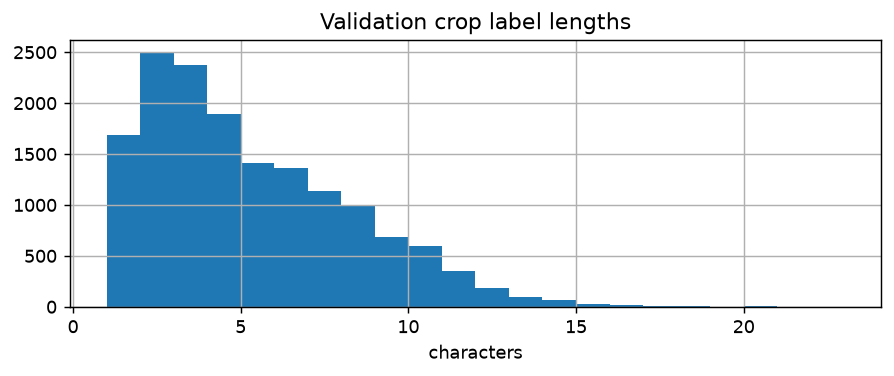

In [11]:
import hashlib
from collections import defaultdict
label_lengths = pd.Series([len(value) for value in labels.values()])
duplicate_bytes = defaultdict(list)
for image in crop_paths:
    digest = hashlib.sha256(image.read_bytes()).hexdigest()
    duplicate_bytes[digest].append(image.relative_to(DATA).as_posix())
cross_video_identical = [
    group for group in duplicate_bytes.values()
    if len(group) > 1 and len({tuple(Path(key).parts[2:4]) for key in group}) > 1
]
print('unique_label_strings', len(set(labels.values())),
      'one_character_labels', int((label_lengths == 1).sum()),
      'exact_crop_groups_cross_video', len(cross_video_identical))
print('label_length_quantiles', label_lengths.quantile([0,.25,.5,.75,.95,1]).to_dict())
print('invalid_box_examples', invalid_boxes[:5])
print('xml_mismatch_examples', frame_df.loc[frame_df.xml_size_mismatch, ['course','video','image']].to_dict('records'))
print('cross_video_identical_crop_examples', cross_video_identical[:3])
fig, ax = plt.subplots(figsize=(7,3))
label_lengths.hist(bins=range(1, int(label_lengths.max()) + 2), ax=ax)
ax.set_title('Validation crop label lengths')
ax.set_xlabel('characters')
plt.tight_layout(); plt.show()


Coverage: validation crops 15379 source videos 140 courses 5
Crops per video quantiles: {0.0: 4.0, 0.1: 25.9, 0.25: 40.0, 0.5: 93.5, 0.75: 148.25, 0.9: 237.60000000000005, 1.0: 435.0}


,crops,videos,characters,one_char,median_width,median_height,crop_share_pct,one_char_pct
course,,,,,,,,
11,2907,36,10820,674,33.0,28.0,18.90,23.19
13,1452,23,7318,74,64.0,36.0,9.44,5.10
19,7757,46,39713,487,57.0,24.0,50.44,6.28
2,1875,28,9080,315,80.0,32.0,12.19,16.80
6,1388,7,6724,134,51.0,31.0,9.03,9.65


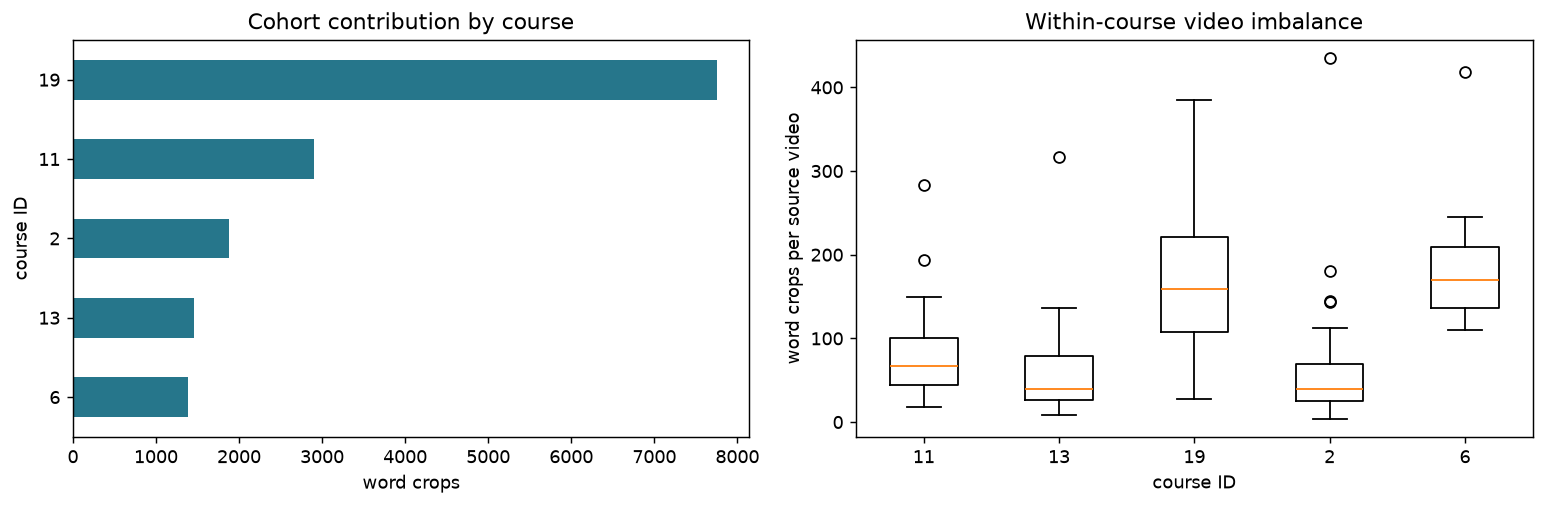

In [11]:
import numpy as np
crop_records = []
for path in crop_paths:
    rel = path.relative_to(CROPS).parts
    key = path.relative_to(DATA).as_posix()
    with Image.open(path) as im:
        width, height = im.size
        gray = np.asarray(im.convert('L'), dtype=np.float32)
    label = labels[key]
    crop_records.append(dict(crop_id=key, course=rel[0], video=rel[1],
                             label=label, chars=len(label), width=width, height=height,
                             intensity_std=float(gray.std()),
                             has_digit=any(ch.isdigit() for ch in label),
                             has_punctuation=any(not ch.isalnum() and not ch.isspace() for ch in label),
                             has_non_ascii=any(ord(ch) > 127 for ch in label)))
crop_df = pd.DataFrame(crop_records)
video_df = crop_df.groupby(['course','video']).agg(crops=('crop_id','size'),
                                                  characters=('chars','sum')).reset_index()
course_df = crop_df.groupby('course').agg(crops=('crop_id','size'), videos=('video','nunique'),
                                           characters=('chars','sum'), one_char=('chars',lambda s:(s==1).sum()),
                                           median_width=('width','median'),median_height=('height','median'))
course_df['crop_share_pct'] = 100 * course_df.crops / len(crop_df)
course_df['one_char_pct'] = 100 * course_df.one_char / course_df.crops
print('Coverage: validation crops',len(crop_df),'source videos',len(video_df),'courses',len(course_df))
print('Crops per video quantiles:',video_df.crops.quantile([0,.1,.25,.5,.75,.9,1]).to_dict())
display(course_df.round(2))
fig, axes = plt.subplots(1,2,figsize=(12,4))
course_df.crops.sort_values().plot.barh(ax=axes[0],color='#26768b')
axes[0].set(xlabel='word crops',ylabel='course ID',title='Cohort contribution by course')
axes[1].boxplot([video_df.loc[video_df.course==course,'crops'] for course in course_df.index],
                tick_labels=list(course_df.index),showfliers=True)
axes[1].set(xlabel='course ID',ylabel='word crops per source video',title='Within-course video imbalance')
plt.tight_layout(); plt.show()

Pixel-intensity std is a descriptive proxy, not a ground-truth image-quality label.
Extreme geometry examples:


,crops,one_char,digit,punctuation,non_ascii,width_p10,width_median,width_p90,height_median,intensity_std_median,one_char_pct,digit_pct,punctuation_pct,non_ascii_pct
course,,,,,,,,,,,,,,
11,2907,674,1185,85,0,16.0,33.0,91.0,28.0,34.21,23.19,40.76,2.92,0.0
13,1452,74,52,23,0,33.0,64.0,131.9,36.0,47.02,5.10,3.58,1.58,0.0
19,7757,487,138,108,0,22.0,57.0,121.0,24.0,89.14,6.28,1.78,1.39,0.0
2,1875,315,182,26,0,26.0,80.0,180.0,32.0,39.49,16.80,9.71,1.39,0.0
6,1388,134,74,197,0,25.0,51.0,91.0,31.0,43.13,9.65,5.33,14.19,0.0


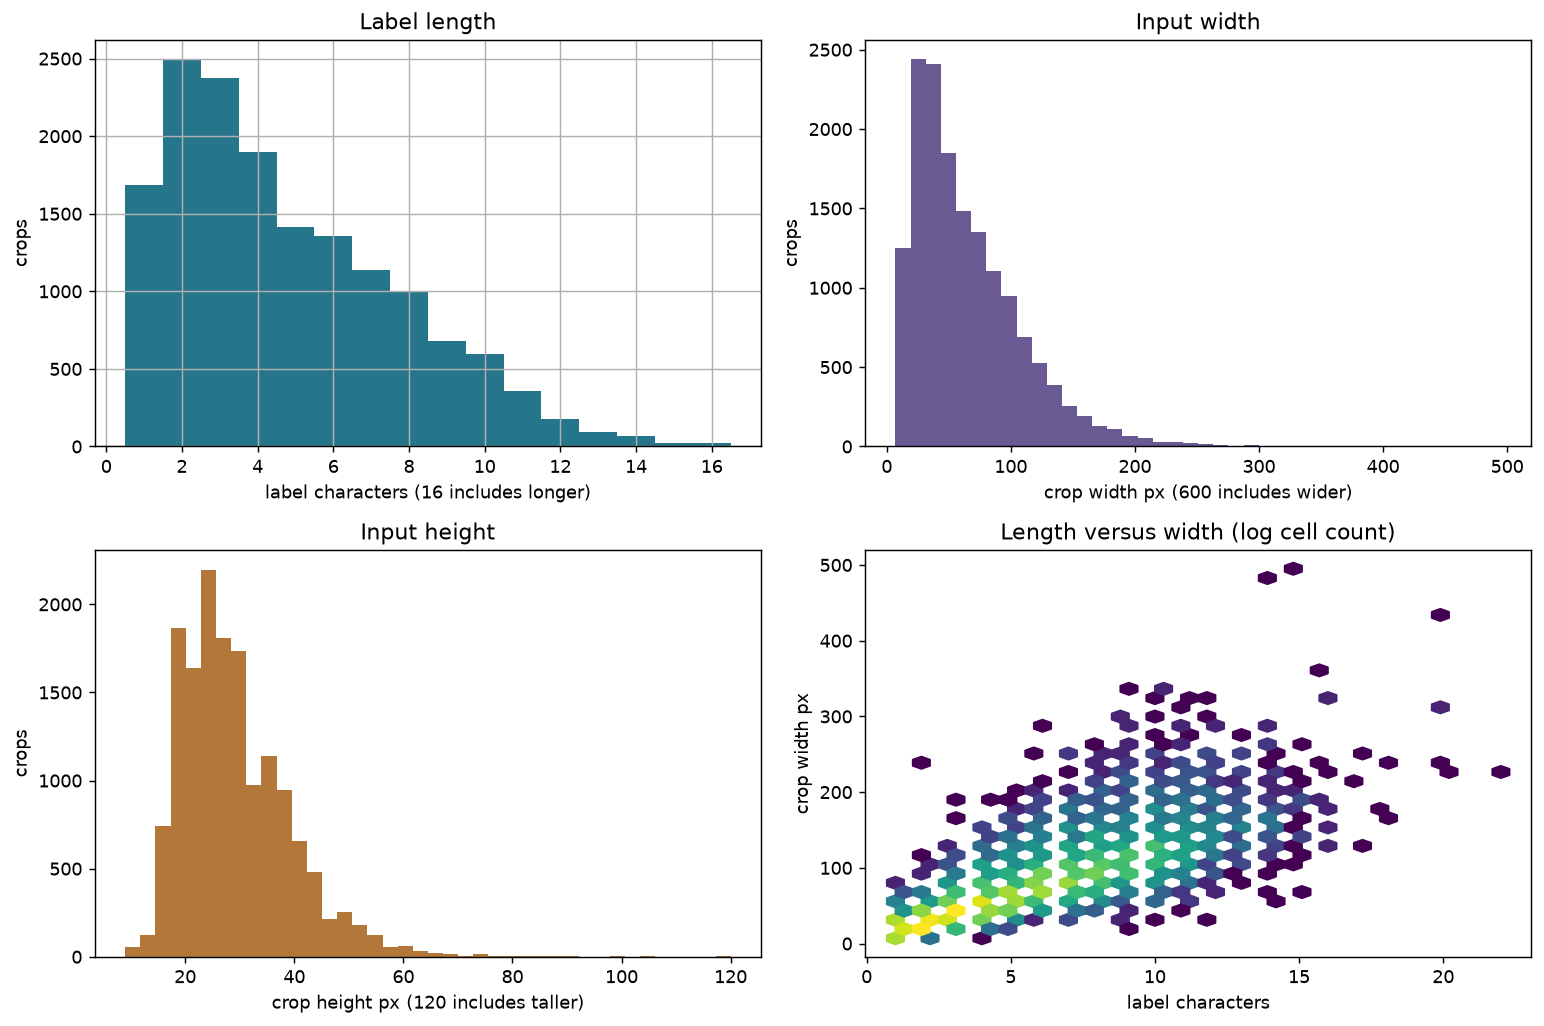

,crop_id,label,width,height,pixels_per_char
6781,Crops/val/19/23/2423.png,interacts,22,38,2.444444
6790,Crops/val/19/23/2432.png,interacts,26,35,2.888889
8388,Crops/val/19/31/4030.png,childminders,35,26,2.916667
7977,Crops/val/19/30/3619.png,group,15,27,3.000000
5574,Crops/val/19/16/1216.png,immediate,28,19,3.111111
10695,Crops/val/19/41/6337.png,lori,13,21,3.250000
1389,Crops/val/11/27/1390.png,primordial,36,14,3.600000
2401,Crops/val/11/36/2402.png,20+18+20+16=70,59,37,4.214286


,crop_id,label,width,height
12147,Crops/val/2/1/38.png,rumplestiltskin,495,97
12150,Crops/val/2/1/40.png,representation,486,74
4966,Crops/val/19/11/608.png,internationalization,431,26
12222,Crops/val/2/12/107.png,back propagation,359,47
12238,Crops/val/2/13/123.png,algorithms,340,55
13934,Crops/val/2/8/1819.png,reassessed,339,46
12235,Crops/val/2/13/120.png,evolution,332,46
5084,Crops/val/19/12/726.png,pseudorandomness,332,50


In [11]:
crop_df['pixels_per_char'] = crop_df.width / crop_df.chars
feature_table = crop_df.groupby('course').agg(
    crops=('crop_id','size'), one_char=('chars',lambda s:(s==1).sum()),
    digit=('has_digit','sum'), punctuation=('has_punctuation','sum'),
    non_ascii=('has_non_ascii','sum'), width_p10=('width',lambda s:s.quantile(.1)),
    width_median=('width','median'), width_p90=('width',lambda s:s.quantile(.9)),
    height_median=('height','median'), intensity_std_median=('intensity_std','median'))
for name in ('one_char','digit','punctuation','non_ascii'):
    feature_table[name+'_pct'] = 100*feature_table[name]/feature_table.crops
print('Pixel-intensity std is a descriptive proxy, not a ground-truth image-quality label.')
display(feature_table.round(2))
fig, axes = plt.subplots(2,2,figsize=(12,8))
crop_df.chars.clip(upper=16).hist(bins=np.arange(.5,17.5),ax=axes[0,0],color='#26768b')
axes[0,0].set(xlabel='label characters (16 includes longer)',ylabel='crops',title='Label length')
axes[0,1].hist(crop_df.width.clip(upper=600),bins=40,color='#695a94')
axes[0,1].set(xlabel='crop width px (600 includes wider)',ylabel='crops',title='Input width')
axes[1,0].hist(crop_df.height.clip(upper=120),bins=40,color='#b37739')
axes[1,0].set(xlabel='crop height px (120 includes taller)',ylabel='crops',title='Input height')
axes[1,1].hexbin(crop_df.chars,crop_df.width,gridsize=35,mincnt=1,bins='log',cmap='viridis')
axes[1,1].set(xlabel='label characters',ylabel='crop width px',title='Length versus width (log cell count)')
plt.tight_layout(); plt.show()
print('Extreme geometry examples:')
display(crop_df.sort_values('pixels_per_char')[['crop_id','label','width','height','pixels_per_char']].head(8))
display(crop_df.sort_values('width',ascending=False)[['crop_id','label','width','height']].head(8))

Gallery crop IDs and labels:


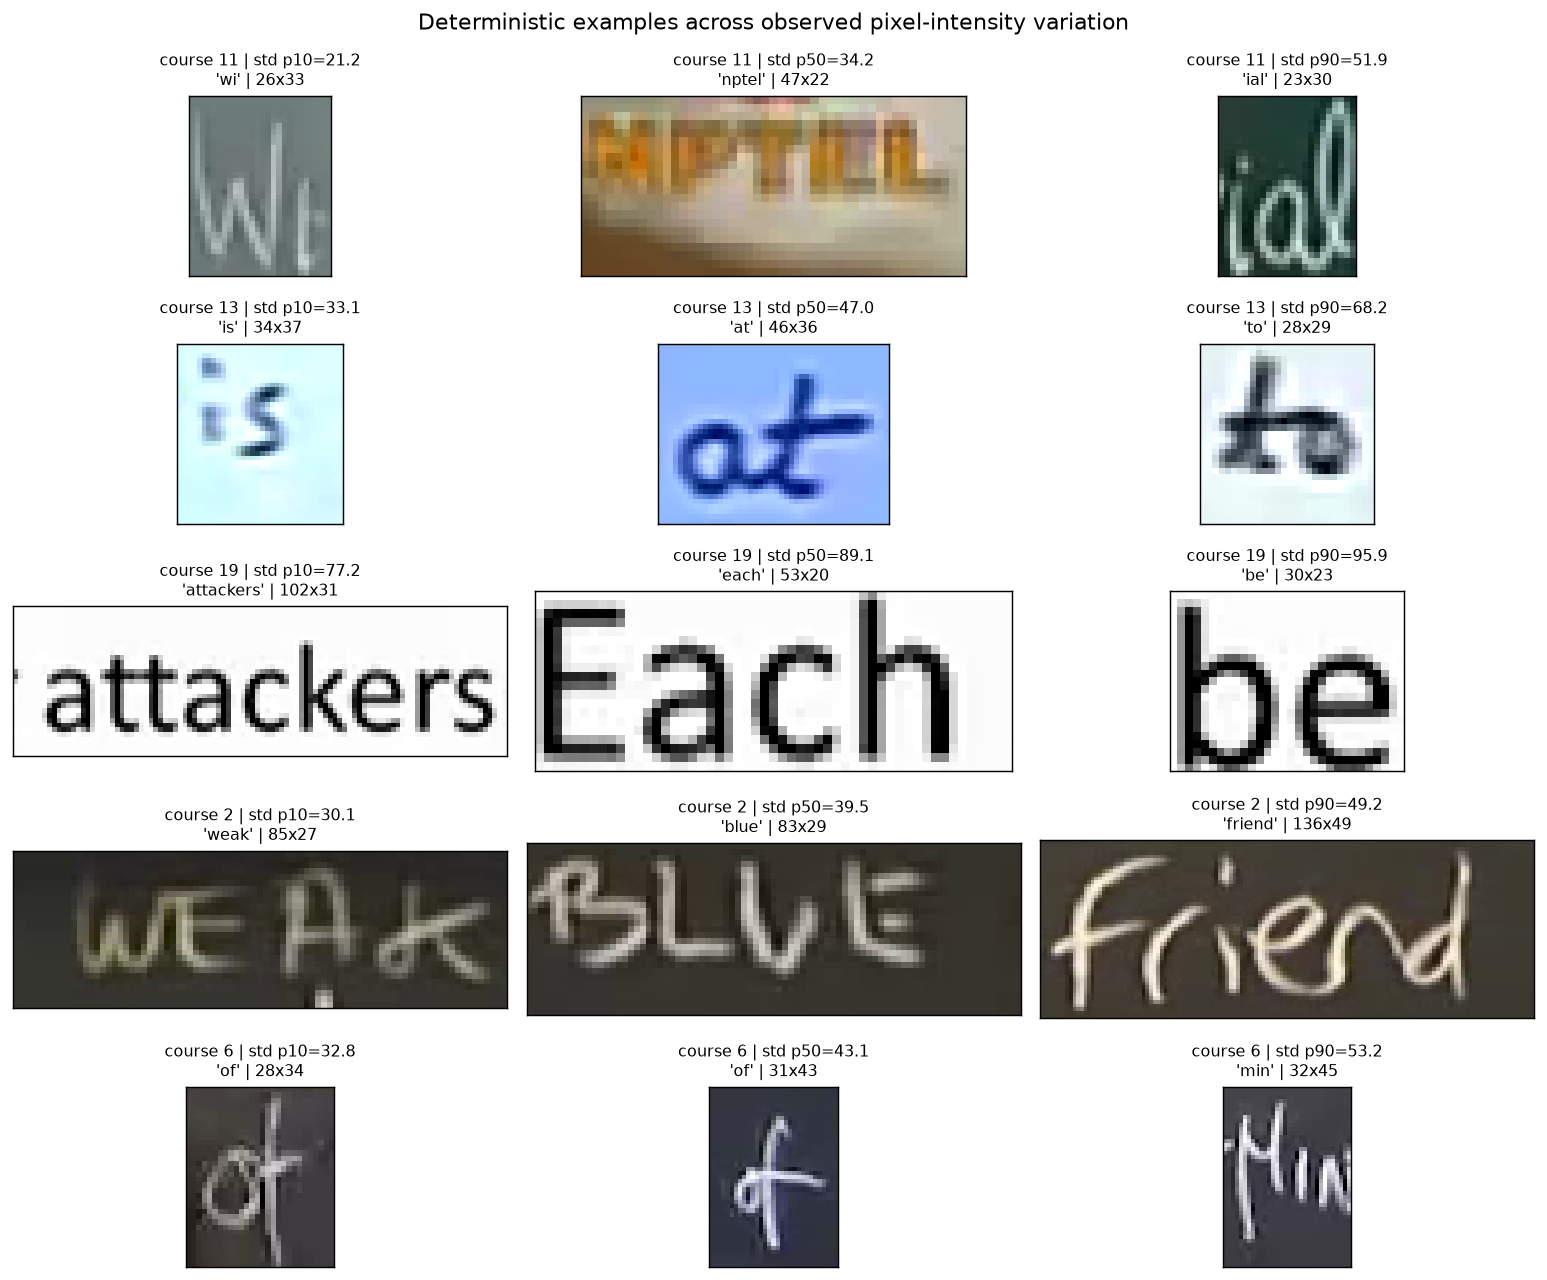

,course,quantile,crop_id,label,width,height,intensity_std
0,11,0.1,Crops/val/11/4/2435.png,wi,26,33,21.178261
1,11,0.5,Crops/val/11/7/2607.png,nptel,47,22,34.208847
2,11,0.9,Crops/val/11/8/2716.png,ial,23,30,51.920372
3,13,0.1,Crops/val/13/9/1434.png,is,34,37,33.122749
4,13,0.5,Crops/val/13/5/1009.png,at,46,36,47.016972
5,13,0.9,Crops/val/13/21/737.png,to,28,29,68.197441
6,19,0.1,Crops/val/19/11/418.png,attackers,102,31,77.186607
7,19,0.5,Crops/val/19/34/4728.png,each,53,20,89.135773
8,19,0.9,Crops/val/19/7/7493.png,be,30,23,95.924812
9,2,0.1,Crops/val/2/17/257.png,weak,85,27,30.085865


In [11]:
# Fixed rule: for each course choose the nearest crop to the 10th, 50th and 90th
# percentile of intensity std; ties break by crop_id. This is not a quality label.
choices = []
for course, group in crop_df.groupby('course'):
    for quantile in (.1,.5,.9):
        target = group.intensity_std.quantile(quantile)
        pick = group.assign(distance=(group.intensity_std-target).abs()).sort_values(
            ['distance','crop_id']).iloc[0]
        choices.append((course,quantile,pick))
fig, axes = plt.subplots(len(course_df),3,figsize=(12,10))
for ax,(course,quantile,row) in zip(axes.flat,choices):
    with Image.open(DATA / row.crop_id) as im:
        ax.imshow(im.convert('RGB'))
    ax.set_title(f'course {course} | std p{int(quantile*100)}={row.intensity_std:.1f}\n'
                 f'{row.label[:30]!r} | {row.width}x{row.height}',fontsize=9)
    ax.set_xticks([]); ax.set_yticks([])
plt.suptitle('Deterministic examples across observed pixel-intensity variation',fontsize=12)
plt.tight_layout(); plt.show()
print('Gallery crop IDs and labels:')
display(pd.DataFrame([dict(course=course,quantile=quantile,crop_id=row.crop_id,
                           label=row.label,width=row.width,height=row.height,
                           intensity_std=row.intensity_std) for course,quantile,row in choices]))

In [11]:
# dHash is a candidate screen only. Shared short words and uniform backgrounds
# can look alike; these pairs are not proof of duplicate source content.
from collections import defaultdict
buckets = defaultdict(list)
hashes = {}
for path in crop_paths:
    key = path.relative_to(DATA).as_posix()
    with Image.open(path) as im:
        small = np.asarray(im.convert('L').resize((9,8)))
    bits = small[:,:-1] > small[:,1:]
    value = sum(int(bit)<<i for i,bit in enumerate(bits.flat))
    hashes[key] = value
    for segment in range(4):
        buckets[(segment,(value>>(16*segment))&65535)].append(key)
candidate_pairs = set()
for group in buckets.values():
    if len(group) > 400:
        continue  # Uniform/low-information buckets produce non-diagnostic pair explosions.
    for i,left in enumerate(group):
        for right in group[i+1:]:
            if tuple(Path(left).parts[2:4]) != tuple(Path(right).parts[2:4]):
                candidate_pairs.add(tuple(sorted((left,right))))
near_pairs = [(left,right,(hashes[left]^hashes[right]).bit_count())
              for left,right in candidate_pairs
              if (hashes[left]^hashes[right]).bit_count() <= 5]
near_pairs.sort(key=lambda item:(item[2],item[0],item[1]))
print('Cross-video exact-byte groups:',len(cross_video_identical))
print('Skipped low-information dHash buckets (>400 items):',sum(len(group)>400 for group in buckets.values()))
print('Cross-video dHash candidate pairs <=5 bits:',len(near_pairs),
      '(screen only; buckets >400 skipped)')
print('Candidate examples with source labels:')
display(pd.DataFrame([dict(left=left,left_label=labels[left],right=right,
                           right_label=labels[right],hamming=distance)
                      for left,right,distance in near_pairs[:20]]))

Cross-video exact-byte groups: 0
Skipped low-information dHash buckets (>400 items): 0
Cross-video dHash candidate pairs <=5 bits: 10251 (screen only; buckets >400 skipped)
Candidate examples with source labels:


,left,left_label,right,right_label,hamming
0,Crops/val/19/1/99.png,the,Crops/val/19/22/2166.png,the,0
1,Crops/val/19/10/391.png,the,Crops/val/19/4/6187.png,the,0
2,Crops/val/19/10/391.png,the,Crops/val/19/43/6673.png,the,0
3,Crops/val/19/10/391.png,the,Crops/val/19/5/7121.png,the,0
4,Crops/val/19/11/539.png,three,Crops/val/19/22/2242.png,three,0
5,Crops/val/19/11/542.png,gen:,Crops/val/19/22/2247.png,gen,0
6,Crops/val/19/11/542.png,gen:,Crops/val/19/41/6330.png,gen,0
7,Crops/val/19/11/545.png,input,Crops/val/19/22/2246.png,input,0
8,Crops/val/19/11/552.png,takes,Crops/val/19/41/6311.png,takes,0
9,Crops/val/19/11/554.png,as,Crops/val/19/41/6347.png,as,0


dHash candidate screen by label/course agreement:
Different-label candidate pairs: 1163 unique involved crops: 537
Review queue: C:\Users\hung\Documents\GitHub\multimodal-lecture-summarizer\benchmark\experiments\outputs\ocr_validation_261009\eda_dhash_different_label_review.csv (candidate pairs, not corrected labels)
Candidate counts by Hamming distance:
Fixed-rule differing-label review rows: 12
Small width-per-character source examples (inspection only):


,same_course,same_label,candidate_pairs
0,True,False,1163
1,True,True,9088


,hamming,candidate_pairs
0,0,213
1,1,653
2,2,1478
3,3,2266
4,4,2687
5,5,2954


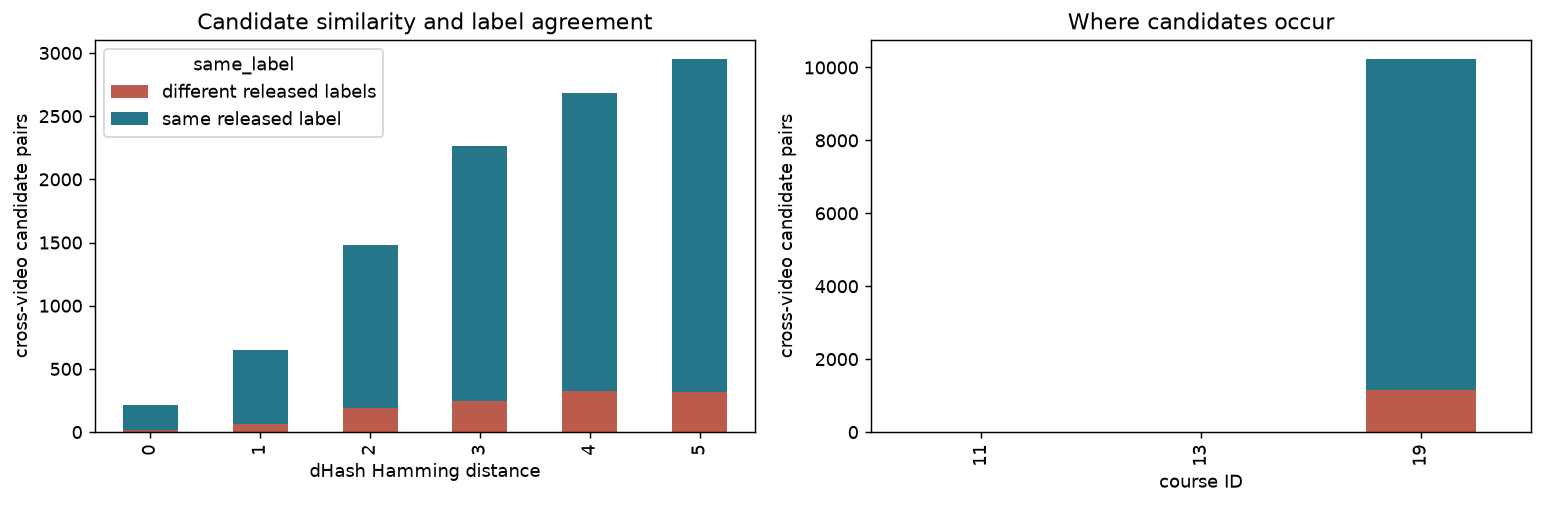

,left,left_label,right,right_label,hamming
0,Crops/val/19/11/542.png,gen:,Crops/val/19/22/2247.png,gen,0
1,Crops/val/19/14/886.png,in,Crops/val/19/25/2687.png,ln,0
2,Crops/val/19/12/692.png,the,Crops/val/19/16/1165.png,thee,1
3,Crops/val/19/13/843.png,all,Crops/val/19/9/7699.png,fall,1
4,Crops/val/19/11/592.png,the,Crops/val/19/2/1672.png,key,2
5,Crops/val/19/11/600.png,the,Crops/val/19/2/1672.png,key,2
6,Crops/val/13/18/328.png,oct,Crops/val/13/3/839.png,ccu,3
7,Crops/val/19/11/420.png,ito,Crops/val/19/34/4826.png,to,3
8,Crops/val/13/11/118.png,och,Crops/val/13/18/361.png,oct,4
9,Crops/val/13/18/340.png,oct,Crops/val/13/3/839.png,ccu,4


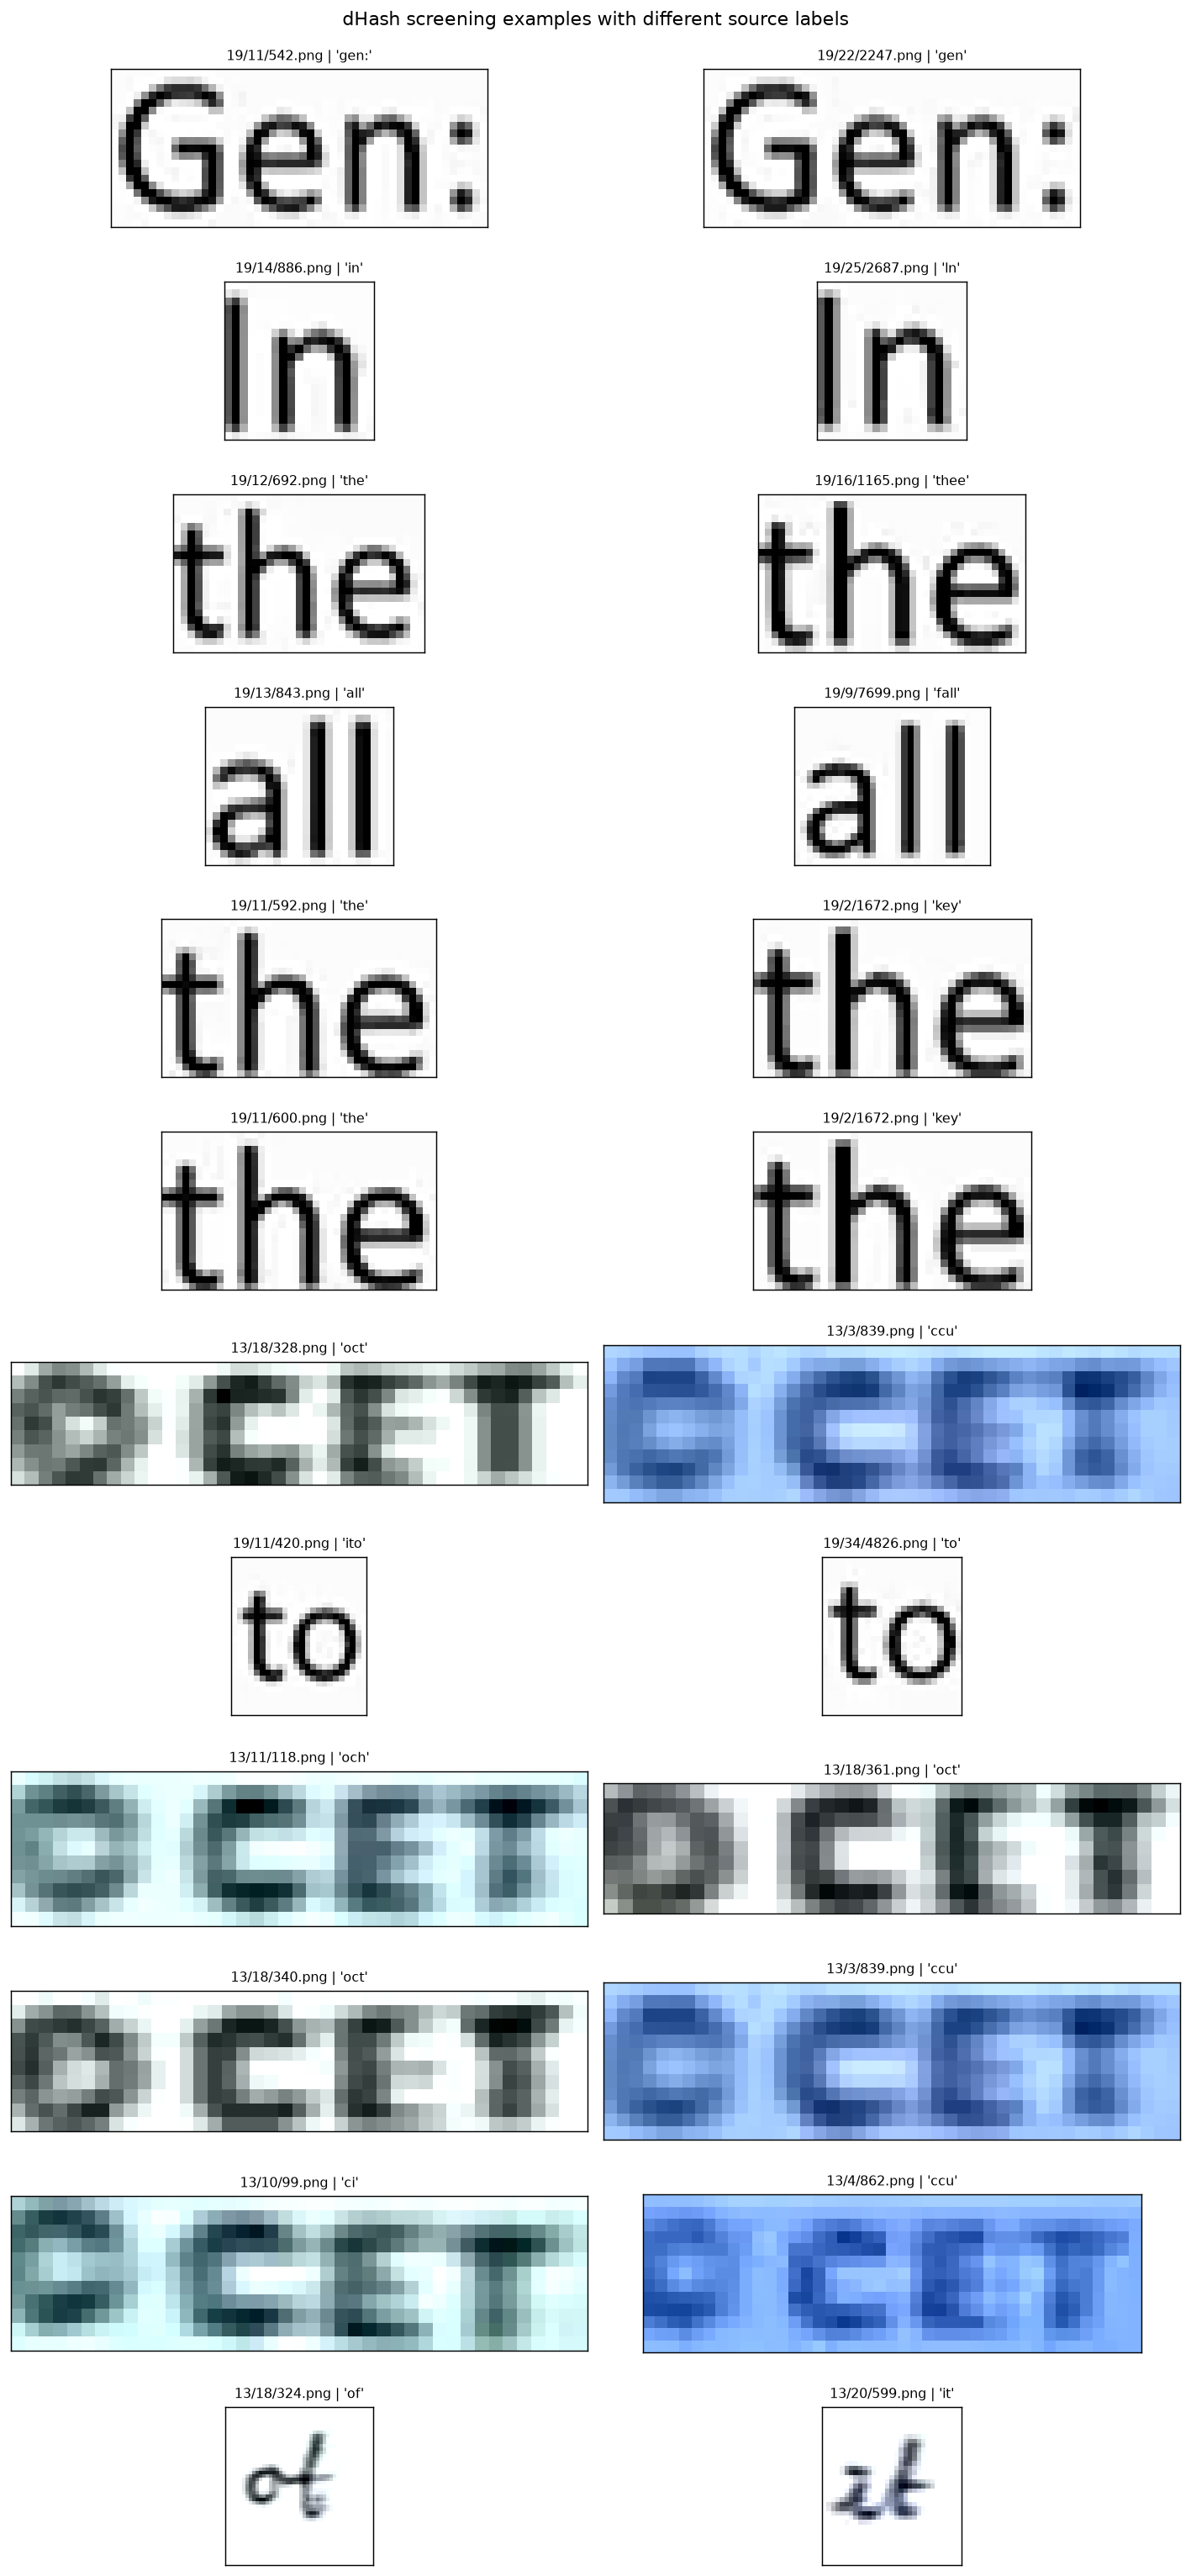

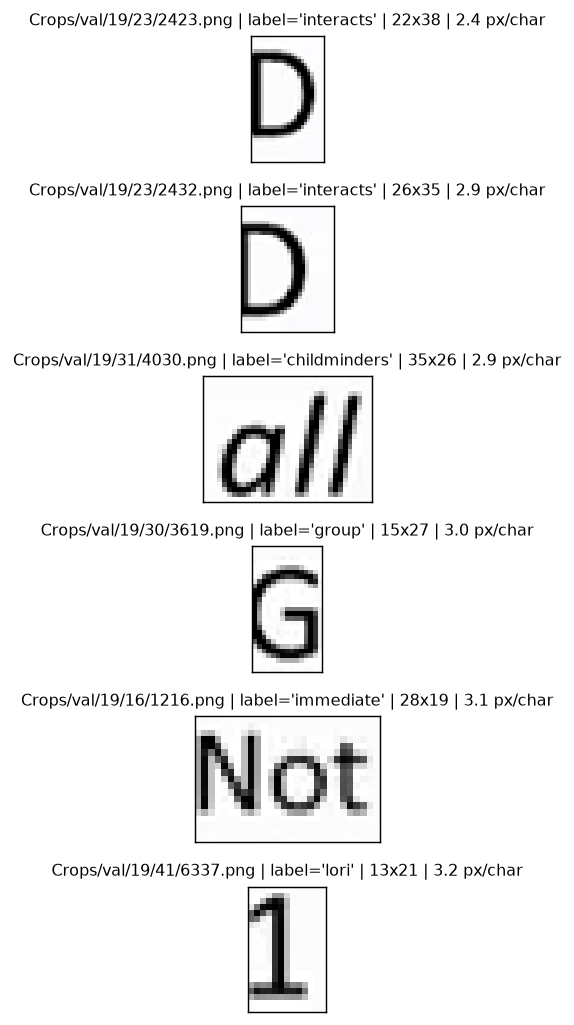

In [11]:
near_df = pd.DataFrame([dict(left=left,right=right,hamming=distance,
                             left_label=labels[left],right_label=labels[right],
                             same_label=labels[left]==labels[right],
                             same_course=Path(left).parts[2]==Path(right).parts[2])
                        for left,right,distance in near_pairs])
print('dHash candidate screen by label/course agreement:')
different_label = near_df[~near_df.same_label]
affected_ids = set(different_label.left) | set(different_label.right)
print('Different-label candidate pairs:',len(different_label),'unique involved crops:',len(affected_ids))
review_queue = ROOT / 'experiments/outputs/ocr_validation_261009/eda_dhash_different_label_review.csv'
review_queue.parent.mkdir(parents=True,exist_ok=True)
different_label.sort_values(['hamming','left','right']).to_csv(review_queue,index=False)
print('Review queue:',review_queue,'(candidate pairs, not corrected labels)')
display(near_df.groupby(['same_course','same_label']).size().rename('candidate_pairs').reset_index())
print('Candidate counts by Hamming distance:')
display(near_df.groupby('hamming').size().rename('candidate_pairs').reset_index())
near_df['course'] = near_df.left.map(lambda key: Path(key).parts[2])
by_distance = near_df.groupby(['hamming','same_label']).size().unstack(fill_value=0)
by_distance = by_distance.rename(columns={False:'different released labels',True:'same released label'})
by_course = near_df.groupby(['course','same_label']).size().unstack(fill_value=0)
by_course = by_course.rename(columns={False:'different released labels',True:'same released label'})
fig,axes=plt.subplots(1,2,figsize=(12,4))
by_distance.plot.bar(stacked=True,ax=axes[0],color=['#ba5b4b','#26768b'])
by_course.plot.bar(stacked=True,ax=axes[1],color=['#ba5b4b','#26768b'])
axes[0].set(xlabel='dHash Hamming distance',ylabel='cross-video candidate pairs',title='Candidate similarity and label agreement')
axes[1].set(xlabel='course ID',ylabel='cross-video candidate pairs',title='Where candidates occur')
axes[1].legend().remove()
plt.tight_layout(); plt.show()
# Fixed audit: choose the first two pairs at each distance 0..5 with different
# released labels. This displays potential label inconsistency or hash collision;
# a human cannot infer a duplicate from the dHash score alone.
review = []
for distance in range(6):
    group = near_df[(near_df.hamming==distance)&(~near_df.same_label)].sort_values(['left','right']).drop_duplicates('left')
    review.extend(group.head(2).to_dict('records'))
print('Fixed-rule differing-label review rows:',len(review))
display(pd.DataFrame(review)[['left','left_label','right','right_label','hamming']])
if review:
    fig, axes = plt.subplots(len(review),2,figsize=(11,max(6,2.0*len(review))))
    for row, pair in zip(axes,review):
        for ax,side in zip(row,('left','right')):
            with Image.open(DATA / pair[side]) as im:
                ax.imshow(im.convert('RGB'))
            short_id = "/".join(Path(pair[side]).parts[2:])
            ax.set_title(f"{short_id} | {pair[side+'_label']!r}",fontsize=9)
            ax.set_xticks([]); ax.set_yticks([])
    plt.suptitle('dHash screening examples with different source labels',fontsize=12)
    plt.tight_layout(rect=(0,0,1,.985),h_pad=2.2); plt.show()
print('Small width-per-character source examples (inspection only):')
thin = crop_df.sort_values(['pixels_per_char','crop_id']).head(6)
fig, axes = plt.subplots(len(thin),1,figsize=(10,8))
for ax,(_,row) in zip(axes,thin.iterrows()):
    with Image.open(DATA / row.crop_id) as im:
        ax.imshow(im.convert('RGB'))
    ax.set_title(f"{row.crop_id} | label={row.label!r} | {row.width}x{row.height} | "
                 f"{row.pixels_per_char:.1f} px/char",fontsize=9)
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

In [11]:
decision = 'KEEP recognition crops with annotation-review flag' if (
    not missing_xml and not missing_crop_labels and not orphan_labels
    and not duplicate_label_keys and not bad_crops and all(labels.values())
) else 'REPAIR/HOLD crop cohort'
print('Decision:', decision)
print('Box-invalid and XML-size-mismatch records remain excluded from any box/spotting benchmark until adjudicated.')
print('This validation-only EDA does not qualify test split or establish OCR model quality.')
print('Near-duplicate dHash pairs are review candidates, never automatic exclusions; differing labels need creator/reference review.')


Decision: KEEP recognition crops with annotation-review flag
Box-invalid and XML-size-mismatch records remain excluded from any box/spotting benchmark until adjudicated.
This validation-only EDA does not qualify test split or establish OCR model quality.
Near-duplicate dHash pairs are review candidates, never automatic exclusions; differing labels need creator/reference review.


## Validation frame anomaly adjudication (2026-10-10)

Rules fixed before the scan below: (1) keep a frame if its PNG decodes, XML parses, all object names are nonempty, all boxes lie within decoded PNG dimensions, and XML size matches; (2) for a **size-field-only** discrepancy with those same checks satisfied, use the decoded PNG dimensions in derived evaluation metadata, preserve original XML, and mark `REPAIR_METADATA_DERIVED`; (3) hold the entire frame from a frame-level box/spotting cohort if any box is outside decoded image bounds, including a one-pixel overrun; never silently clip it. This geometry screen does not independently prove text transcriptions. It does not alter the published crop-recognition cohort.

The local source contains only validation. Historical train/test anomaly and dHash counts are shown separately as receipt-derived context, not new per-ID judgments. dHash is a candidate screen only; missing train/test frames and full pair IDs prevent cross-split adjudication here. Native test references were previously inspected, so no future test result is called unseen.

Validation decisions: {'KEEP': 543, 'REPAIR_METADATA_DERIVED': 3, 'HOLD_BOX_OR_LABEL': 3}
selected 549 observed 549 label_valid_geometry 546 media_valid_png 549 evaluated_frame_box 0 failed_acquisition_or_parse 0
Per-ID ledger: C:\Users\hung\Documents\GitHub\multimodal-lecture-summarizer\benchmark\plans\reports\ocr-iiit-cvid-validation-frame-adjudication-261010.csv
Historical full-source receipt only; train/test source files absent locally:
Historical cross-split dHash pairs: 469 affected frames: 263 saved example pairs: 20
No automatic cross-split exclusions; full pair list and source frames needed for visual/source-course review.


,frame_id,decision,png_width,png_height,xml_width,xml_height,invalid_object_details
66,11/27/00_45_38_00009.png,REPAIR_METADATA_DERIVED,608,482,2,1,[]
213,19/11/00_16_20_00005.png,REPAIR_METADATA_DERIVED,960,546,2,1,[]
399,2/11/00_04_59_00001.png,REPAIR_METADATA_DERIVED,1280,720,2,1,[]
441,2/23/00_20_38_00006.png,HOLD_BOX_OR_LABEL,1280,720,1280,720,"[{""object_index"": 4, ""label"": ""p5"", ""box"": [1231.0, 479.0, 1281.0, 529.0], ""valid_box"": false}]"
483,6/1/00_43_16_00008.png,HOLD_BOX_OR_LABEL,640,386,640,386,"[{""object_index"": 7, ""label"": ""r-d"", ""box"": [592.0, 86.0, 641.0, 118.0], ""valid_box"": false}]"
521,6/4/01_16_06_00008.png,HOLD_BOX_OR_LABEL,640,386,640,386,"[{""object_index"": 6, ""label"": ""hand"", ""box"": [570.0, 28.0, 641.0, 54.0], ""valid_box"": false}]"


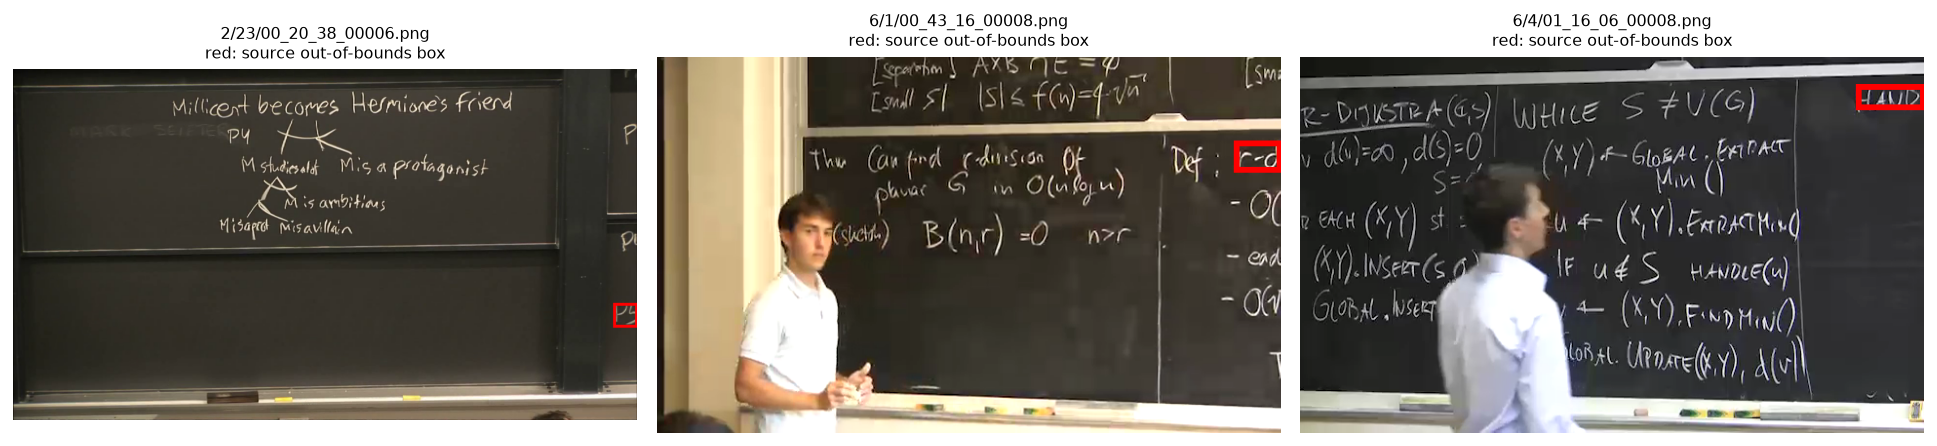

,split,frames,invalid_boxes,invalid_box_frame_ids_saved,xml_size_mismatches,xml_mismatch_ids_saved
0,train,3171,18,16,23,20
1,val,549,3,3,3,3
2,test,1755,1,1,98,20


In [11]:
from pathlib import Path
import csv, json
import xml.etree.ElementTree as ET
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt
from IPython.display import display
import pandas as pd

ledger_rows = []
box_examples = []
for path in frame_paths:
    rel = path.relative_to(FRAMES).as_posix()
    root = ET.parse(path.with_suffix('.xml')).getroot()
    with Image.open(path) as image:
        image.load()
        actual = image.size
    declared = (int(root.findtext('size/width', '0')), int(root.findtext('size/height', '0')))
    objects = root.findall('object')
    issues = []
    for index, obj in enumerate(objects):
        label = (obj.findtext('name') or '').strip()
        box = obj.find('bndbox')
        try:
            coords = tuple(float(box.findtext(key)) for key in ('xmin','ymin','xmax','ymax'))
        except (AttributeError, TypeError, ValueError):
            coords = None
        valid = coords is not None and 0 <= coords[0] < coords[2] <= actual[0] and 0 <= coords[1] < coords[3] <= actual[1]
        if not valid or not label:
            issues.append({'object_index': index, 'label': label, 'box': coords, 'valid_box': bool(valid)})
    size_mismatch = declared != actual
    if issues:
        decision = 'HOLD_BOX_OR_LABEL'
        reason = 'invalid object geometry or blank label; no automatic clipping'
        box_examples.append((path, issues))
    elif size_mismatch:
        decision = 'REPAIR_METADATA_DERIVED'
        reason = 'XML size differs; use decoded PNG dimensions in derived metadata only'
    else:
        decision = 'KEEP'
        reason = 'PNG and XML parsed; nonblank labels and boxes within image bounds'
    ledger_rows.append({'source_split':'val','frame_id':rel,'decision':decision,'reason':reason,
                        'png_width':actual[0],'png_height':actual[1],
                        'xml_width':declared[0],'xml_height':declared[1],
                        'size_mismatch':size_mismatch,'object_count':len(objects),
                        'invalid_objects':len(issues),'invalid_object_details':json.dumps(issues,ensure_ascii=False)})
ledger = pd.DataFrame(ledger_rows)
ledger_path = ROOT / 'plans/reports/ocr-iiit-cvid-validation-frame-adjudication-261010.csv'
ledger.to_csv(ledger_path,index=False,encoding='utf-8')
print('Validation decisions:',ledger.decision.value_counts().to_dict())
print('selected',len(ledger),'observed',len(ledger),'label_valid_geometry',int((ledger.decision!='HOLD_BOX_OR_LABEL').sum()),
      'media_valid_png',len(ledger),'evaluated_frame_box',0,'failed_acquisition_or_parse',0)
print('Per-ID ledger:',ledger_path)
display(ledger.loc[ledger.decision!='KEEP', ['frame_id','decision','png_width','png_height','xml_width','xml_height','invalid_object_details']])

fig,axes=plt.subplots(1,len(box_examples),figsize=(15,4))
for ax,(path,issues) in zip(axes,box_examples):
    with Image.open(path) as source:
        image=source.convert('RGB')
    draw=ImageDraw.Draw(image)
    for issue in issues:
        if issue['box']:
            draw.rectangle(issue['box'],outline='red',width=6)
    ax.imshow(image)
    ax.set_title(path.relative_to(FRAMES).as_posix()+'\nred: source out-of-bounds box',fontsize=9)
    ax.axis('off')
plt.tight_layout();plt.show()

historical = json.loads((ROOT/'experiments/outputs/full_corpus_eda_261003/iiit_cvid.json').read_text())
duplicates = json.loads((ROOT/'experiments/outputs/full_corpus_eda_261003/iiit_cvid_duplicates.json').read_text())
receipt_counts = pd.DataFrame([{'split':x['source_split'],'frames':x['frames'],
  'invalid_boxes':x['invalid_boxes'],'invalid_box_frame_ids_saved':len(x['invalid_box_frames']),
  'xml_size_mismatches':x['xml_size_mismatches'],'xml_mismatch_ids_saved':len(x['xml_size_mismatch_examples'])} for x in historical['frames']])
print('Historical full-source receipt only; train/test source files absent locally:')
display(receipt_counts)
print('Historical cross-split dHash pairs:',duplicates['near_cross_split_pairs'],
      'affected frames:',duplicates['near_cross_split_affected_frames'],
      'saved example pairs:',len(duplicates['near_cross_split_examples']))
print('No automatic cross-split exclusions; full pair list and source frames needed for visual/source-course review.')

## Qualification follow-up — 2026-10-10

Earlier executed outputs are retained as historical evidence. This additive review supersedes their current availability/qualification statements where explicitly recorded in the receipt. KEEP and REPAIR are scoped record-quality decisions, not approval of a benchmark cohort.

**Saved qualification receipt loaded and hash verified.** This cell does not decode media or run models.

,selected,observed,label_valid,media_valid,evaluated,failed
0,5475,5475,5455,5475,0,0


**Status:** full_frame_geometry_review_complete_duplicate_content_and_source_mapping_HOLD

,field,value
0,dataset,"""iiit-cvid"""
1,observed_at_utc,"""2026-10-10T08:51:18.445999+00:00"""
2,model_inference_run,false
3,unseen_reference_claim,false
4,source_archive_sha256,"""b5b562580e250ee3336462b7699bc79d0d1149d3b8cc8..."
5,archive_restored_locally,true
6,split_counts,"{""test"": 1755, ""train"": 3171, ""val"": 549}"
7,decisions,"{""KEEP"": 5335, ""REPAIR"": 120, ""HOLD"": 20}"
8,invalid_boxes,22
9,invalid_frames,20


Evidence: `experiments/outputs/dataset_qualification_261010/iiit-cvid-frame-ledger.csv` · SHA-256 `f2bd1cc64e25a0dac3ebbbc5541caef1068eb4982a2ca6334de87d65c19e7c05`

5475 ledger rows; first 20 shown below. Full ledger remains linked above.

... (11 outputs left out)

811 ledger rows; first 20 shown below. Full ledger remains linked above.

,source_group,records,splits,cross_split,identity_status
0,1/1,11,"[""train""]",False,release_path_group_not_independently_verified_...
1,1/10,13,"[""train""]",False,release_path_group_not_independently_verified_...
2,1/11,17,"[""train""]",False,release_path_group_not_independently_verified_...
3,1/12,12,"[""train""]",False,release_path_group_not_independently_verified_...
4,1/13,12,"[""train""]",False,release_path_group_not_independently_verified_...
5,1/14,9,"[""train""]",False,release_path_group_not_independently_verified_...
6,1/15,12,"[""train""]",False,release_path_group_not_independently_verified_...
7,1/16,12,"[""train""]",False,release_path_group_not_independently_verified_...
8,1/17,10,"[""train""]",False,release_path_group_not_independently_verified_...
9,1/18,11,"[""train""]",False,release_path_group_not_independently_verified_...


Evidence: `experiments/outputs/dataset_qualification_261010/iiit-cvid-read-failures.csv` · SHA-256 `7eb70257593da06f682a3ddda54a9d260d4fc514f645237f5ca74b08f8da61a6`

Evidence: `experiments/outputs/dataset_qualification_261010/iiit-cvid-geometry-contact-sheet.png` · SHA-256 `d4040f66132b486f260ec7d7a213936294cf7303551ed4ce183abe909e005b78`

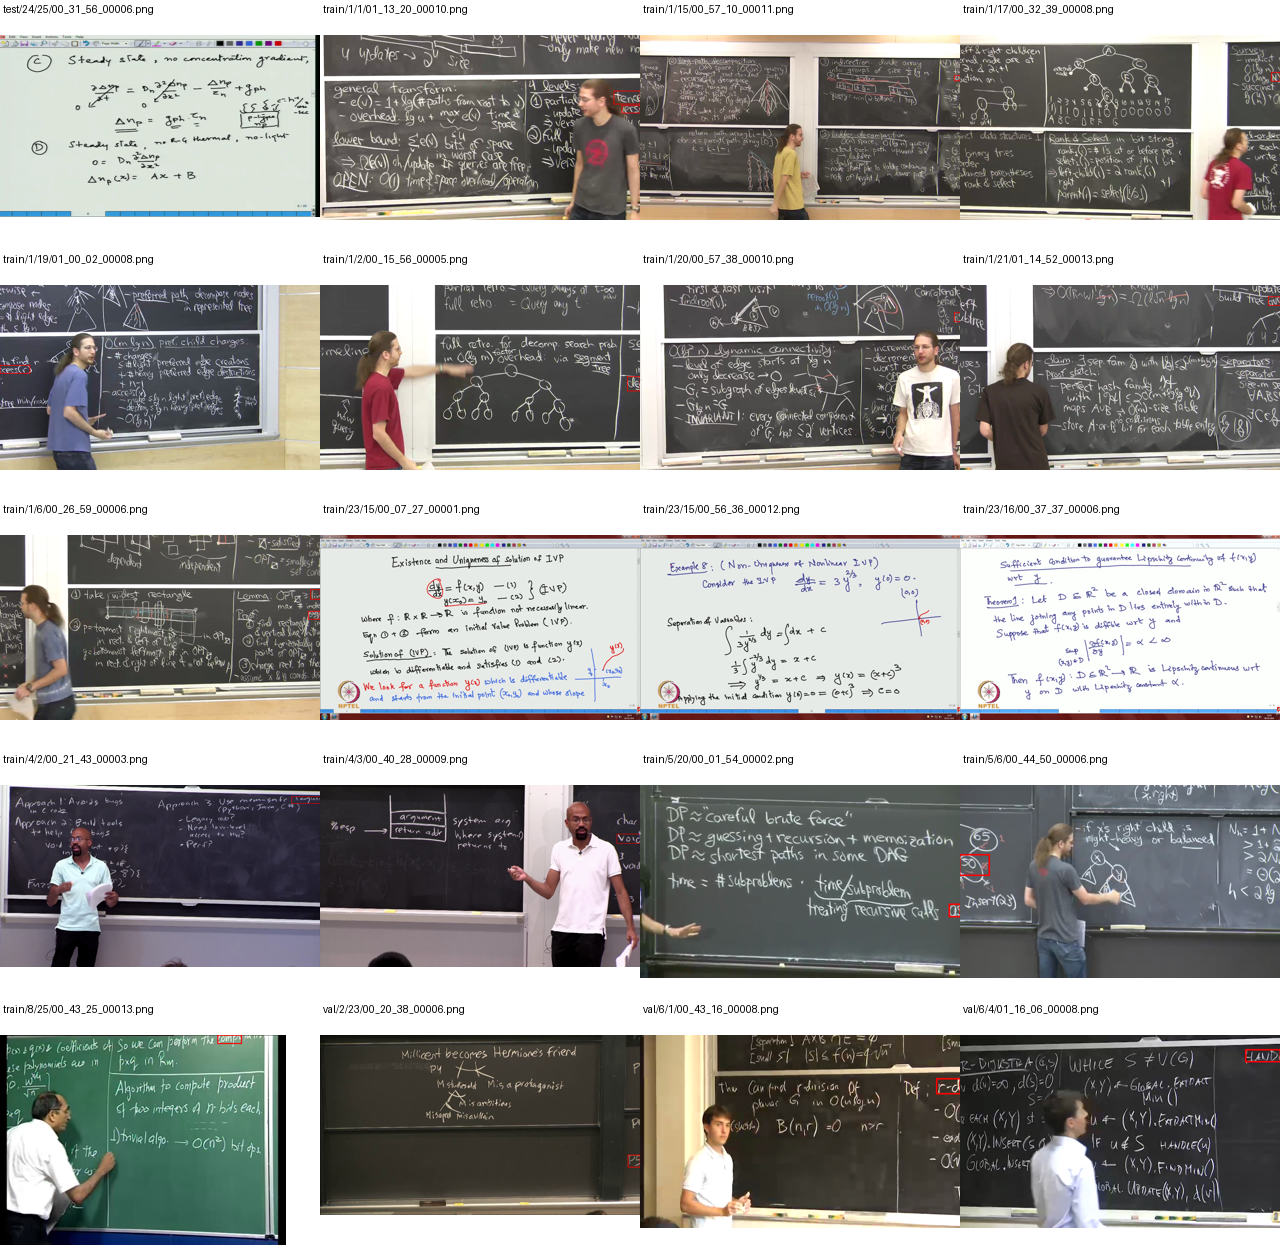

Evidence: `experiments/outputs/dataset_qualification_261010/iiit-cvid-geometry-adjudication.csv` · SHA-256 `3f5b5da582d471344e1e8fe9f5b0818afe2964a60e37a1cd226c8488b854aa70`

22 ledger rows; first 20 shown below. Full ledger remains linked above.

,id,object_index,label,box,actual_size,decision,reason,source_xml_sha256,anomaly_class,review_evidence,resolution,why_not_clip
0,test/24/25/00_31_56_00006.png,36,jle,"[-2, 4, 28, 19]","[1920, 1090]",HOLD,"[""outside_or_nonpositive_geometry""]",25b49cfbdbcef70e1bdb61fefc3e34aa8a8d98aee80d50...,negative_coordinate,full_resolution_decode_and_XML_check; 20_frame...,HOLD_frame_for_geometry_endpoint; original_lab...,image_edge_does_not_establish_author_coordinat...
1,train/1/1/01_13_20_00010.png,8,tence,"[1174, 222, 1281, 276]","[1280, 738]",HOLD,"[""outside_or_nonpositive_geometry""]",028e7cb17e790dc487e379c25acec39ba1384e7ca18204...,right_edge_one_pixel,full_resolution_decode_and_XML_check; 20_frame...,HOLD_frame_for_geometry_endpoint; original_lab...,image_edge_does_not_establish_author_coordinat...
2,train/1/1/01_13_20_00010.png,31,irs,"[1206, 280, 1281, 312]","[1280, 738]",HOLD,"[""outside_or_nonpositive_geometry""]",028e7cb17e790dc487e379c25acec39ba1384e7ca18204...,right_edge_one_pixel,full_resolution_decode_and_XML_check; 20_frame...,HOLD_frame_for_geometry_endpoint; original_lab...,image_edge_does_not_establish_author_coordinat...
3,train/1/15/00_57_10_00011.png,39,rn,"[1256, 160, 1281, 183]","[1280, 738]",HOLD,"[""outside_or_nonpositive_geometry""]",e7517a36d3a52dfdcaa6b09f9187f3b6cceab351898bc3...,right_edge_one_pixel,full_resolution_decode_and_XML_check; 20_frame...,HOLD_frame_for_geometry_endpoint; original_lab...,image_edge_does_not_establish_author_coordinat...
4,train/1/17/00_32_39_00008.png,21,n,"[1244, 148, 1281, 185]","[1280, 738]",HOLD,"[""outside_or_nonpositive_geometry""]",3aaff6762938496c2965aa2c00685eaf0b4821484524e6...,right_edge_one_pixel,full_resolution_decode_and_XML_check; 20_frame...,HOLD_frame_for_geometry_endpoint; original_lab...,image_edge_does_not_establish_author_coordinat...
5,train/1/19/01_00_02_00008.png,14,fessing,"[-1, 319, 120, 353]","[1280, 738]",HOLD,"[""outside_or_nonpositive_geometry""]",015ad02b88064821aaa0b507a4fcf827b0d62dda2b341b...,negative_coordinate,full_resolution_decode_and_XML_check; 20_frame...,HOLD_frame_for_geometry_endpoint; original_lab...,image_edge_does_not_establish_author_coordinat...
6,train/1/2/00_15_56_00005.png,24,de,"[1228, 364, 1281, 423]","[1280, 738]",HOLD,"[""outside_or_nonpositive_geometry""]",20b5e39127f9969c97c33c74d47d1d2b759493a3ac896a...,right_edge_one_pixel,full_resolution_decode_and_XML_check; 20_frame...,HOLD_frame_for_geometry_endpoint; original_lab...,image_edge_does_not_establish_author_coordinat...
7,train/1/20/00_57_38_00010.png,28,b9,"[1256, 109, 1283, 147]","[1280, 738]",HOLD,"[""outside_or_nonpositive_geometry""]",ad3319d4d24b400c4041b36a8623df1d078b72efaaba3f...,other_overflow,full_resolution_decode_and_XML_check; 20_frame...,HOLD_frame_for_geometry_endpoint; original_lab...,image_edge_does_not_establish_author_coordinat...
8,train/1/21/01_14_52_00013.png,28,tv,"[1232, 45, 1281, 82]","[1280, 738]",HOLD,"[""outside_or_nonpositive_geometry""]",a39608ebde9f5f86a7f36c28e6c9c86555ee9da88c9cc3...,right_edge_one_pixel,full_resolution_decode_and_XML_check; 20_frame...,HOLD_frame_for_geometry_endpoint; original_lab...,image_edge_does_not_establish_author_coordinat...
9,train/1/6/00_26_59_00006.png,40,seg,"[1232, 303, 1281, 337]","[1280, 738]",HOLD,"[""outside_or_nonpositive_geometry""]",9afccf24ae90957628590a77dbda68c31a06d0e35beff3...,right_edge_one_pixel,full_resolution_decode_and_XML_check; 20_frame...,HOLD_frame_for_geometry_endpoint; original_lab...,image_edge_does_not_establish_author_coordinat...


Evidence: `experiments/outputs/dataset_qualification_261010/iiit-cvid-derived-dimension-overrides.json` · SHA-256 `b7ded6fb47e0af84d0bfe2434e656ae14ce8f31035462039ffe0ac2d54d7419a`

Evidence: `experiments/outputs/dataset_qualification_261010/iiit-cvid-adjudication-summary.json` · SHA-256 `29269b9ec79b8dbd2c7e69e9eb662bcc30112264890fc2b5c68955fcb4cfee29`

**No scientific cohort/protocol freeze. Native test references inspected in EDA cannot be described as unseen. Evaluated counts here refer to new model evaluations in this follow-up.**

In [12]:
from pathlib import Path
import json, hashlib
import pandas as pd
from IPython.display import display, Markdown, Image
saved = json.loads('{"dataset": "iiit-cvid", "observed_at_utc": "2026-10-10T08:51:18.445999+00:00", "counts": {"selected": 5475, "observed": 5475, "label_valid": 5455, "media_valid": 5475, "evaluated": 0, "failed": 0}, "artifacts": [{"path": "experiments\\\\outputs\\\\dataset_qualification_261010\\\\iiit-cvid-frame-ledger.csv", "sha256": "f2bd1cc64e25a0dac3ebbbc5541caef1068eb4982a2ca6334de87d65c19e7c05", "rows": 5475}, {"path": "experiments\\\\outputs\\\\dataset_qualification_261010\\\\iiit-cvid-box-issue-ledger.csv", "sha256": "f96bd4a80b491c5c155f20f1f55fa19b6d6ddf311df01ab1183511e7be5ec19e", "rows": 22}, {"path": "experiments\\\\outputs\\\\dataset_qualification_261010\\\\iiit-cvid-derived-metadata-ledger.csv", "sha256": "78290250e08449e625809420eff9843f61717acfd74f73cf620bb92b87cc94b7", "rows": 124}, {"path": "experiments\\\\outputs\\\\dataset_qualification_261010\\\\iiit-cvid-cross-split-pairs.csv", "sha256": "541789c71a4a7070289bdecb5a6b7654769e68be82a010d667d60726630aeb65", "rows": 469}, {"path": "experiments\\\\outputs\\\\dataset_qualification_261010\\\\iiit-cvid-source-groups.csv", "sha256": "d4f9605db086c7c22ea2964d2ca15ddbeb2b316a07a5634ca9519bade7558e75", "rows": 811}, {"path": "experiments\\\\outputs\\\\dataset_qualification_261010\\\\iiit-cvid-read-failures.csv", "sha256": "7eb70257593da06f682a3ddda54a9d260d4fc514f645237f5ca74b08f8da61a6", "rows": 0}, {"path": "experiments\\\\outputs\\\\dataset_qualification_261010\\\\iiit-cvid-geometry-contact-sheet.png", "sha256": "d4040f66132b486f260ec7d7a213936294cf7303551ed4ce183abe909e005b78"}, {"path": "experiments\\\\outputs\\\\dataset_qualification_261010\\\\iiit-cvid-geometry-adjudication.csv", "sha256": "3f5b5da582d471344e1e8fe9f5b0818afe2964a60e37a1cd226c8488b854aa70", "rows": 22}, {"path": "experiments\\\\outputs\\\\dataset_qualification_261010\\\\iiit-cvid-derived-dimension-overrides.json", "sha256": "b7ded6fb47e0af84d0bfe2434e656ae14ce8f31035462039ffe0ac2d54d7419a"}, {"path": "experiments\\\\outputs\\\\dataset_qualification_261010\\\\iiit-cvid-adjudication-summary.json", "sha256": "29269b9ec79b8dbd2c7e69e9eb662bcc30112264890fc2b5c68955fcb4cfee29"}], "model_inference_run": false, "unseen_reference_claim": false, "source_archive_sha256": "b5b562580e250ee3336462b7699bc79d0d1149d3b8cc82f1b221a0d0ce4fb489", "archive_restored_locally": true, "split_counts": {"test": 1755, "train": 3171, "val": 549}, "decisions": {"KEEP": 5335, "REPAIR": 120, "HOLD": 20}, "invalid_boxes": 22, "invalid_frames": 20, "XML_size_mismatches": 124, "cross_split_candidate_pairs": 469, "cross_split_source_groups": [], "status": "full_frame_geometry_review_complete_duplicate_content_and_source_mapping_HOLD", "label_valid_scope": "geometry_and_nonblank_names_not_independent_text_correctness", "derived_dimension_overrides": 120, "geometry_adjudication": "22 boxes remain HOLD; no clipping without source-coordinate evidence", "cohort_frozen": false}')
roots = [Path.cwd(), *Path.cwd().parents]
root = next((p for p in roots if (p / "experiments/notebooks/notebook_manifest.yaml").is_file()), None)
receipt_path = root / "experiments/outputs/dataset_qualification_261010/iiit-cvid-qualification-receipt.json" if root else None
if receipt_path is not None and receipt_path.is_file():
    assert hashlib.sha256(receipt_path.read_bytes()).hexdigest() == '5173ec68a60845d0969374f60c1017bb39b861e6b8ea466cefae32086482ad86', "Receipt changed: review and regenerate this section."
    evidence = json.loads(receipt_path.read_text(encoding="utf-8"))
    display(Markdown("**Saved qualification receipt loaded and hash verified.** This cell does not decode media or run models."))
else:
    evidence = saved
    display(Markdown("**Embedded historical snapshot only:** local qualification files unavailable. This is not a new acquisition or audit."))
display(pd.DataFrame([evidence["counts"]]))
display(Markdown("**Status:** " + str(evidence.get("status", "HOLD; cohort not frozen"))))
details = {k:v for k,v in evidence.items() if k not in {"counts", "artifacts"}}
display(pd.DataFrame([{"field":k, "value":json.dumps(v, ensure_ascii=False)} for k,v in details.items()]))
for item in evidence.get("artifacts", []):
    relative = item["path"].replace("\\", "/")
    display(Markdown("Evidence: `" + relative + "` · SHA-256 `" + item["sha256"] + "`"))
    path = root / relative if root else None
    if path is None or not path.is_file():
        continue
    assert hashlib.sha256(path.read_bytes()).hexdigest() == item["sha256"], "Evidence hash changed: " + relative
    if path.suffix == ".csv" and path.stat().st_size > 5:
        table = pd.read_csv(path)
        # Show decisions and coordinates; avoid exposing more answer/reference content.
        safe = [c for c in table.columns if c not in {"reference_text", "question", "answer"}]
        display(Markdown(str(len(table)) + " ledger rows; first 20 shown below. Full ledger remains linked above."))
        display(table[safe].head(20))
    elif path.name.endswith("geometry-contact-sheet.png"):
        display(Image(filename=str(path), width=1000))
display(Markdown("**No scientific cohort/protocol freeze. Native test references inspected in EDA cannot be described as unseen. Evaluated counts here refer to new model evaluations in this follow-up.**"))
